# 신림 시장권 | 주거 귀가형

* 대상: 관악신사시장(신사동), 관악종합시장(신원동), 신림현대종합상가(서림동), 우림시장(난곡동)
* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 4곳이 있는 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, SILLIM_DONGS, SILLIM_SHARES, SILLIM_HOME_HOURS, SILLIM_HOME_EVENING,
                      plot_sillim_purpose, plot_sillim_time)

## 방문·체류 목적·연령

,도착 OD 중 귀가,체류 STAY 중 귀가,체류 STAY 중 20·30대
신사동,82.2,78.4,29.9
신원동,78.6,83.5,29.8
서림동,91.0,83.8,47.0
난곡동,93.1,89.3,26.1
전국 평균,55.7,65.0,26.3


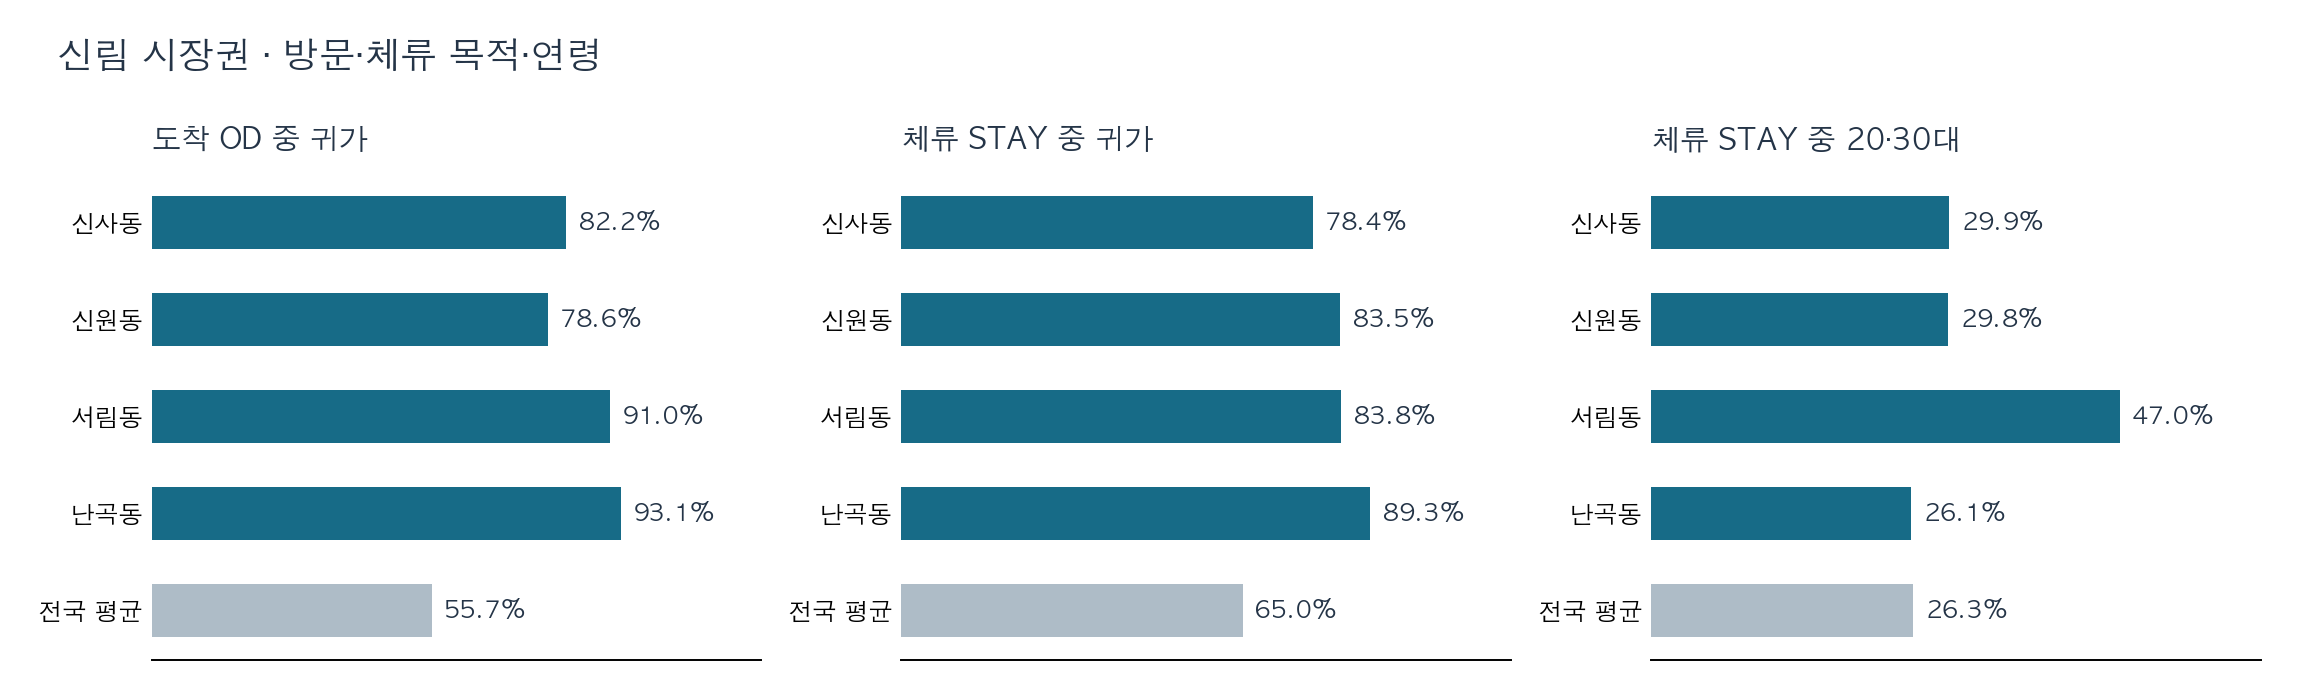

In [2]:
display(pd.DataFrame({title: values + [national] for title, (values, national) in SILLIM_SHARES.items()},
                     index=SILLIM_DONGS + ["전국 평균"]))
plot_sillim_purpose()
display(Image(filename=str(FIGS / "fig_v4_3a_sillim_purpose.png")))

## 시장 위치

* 지도: 비공개 시장 위치·행정동 경계 입력으로 작성한 저장 결과
* 재생성: 비공개 입력 경로 지정 시 가능

비공개 시장 위치 입력이 없어 저장된 그림을 표시합니다.


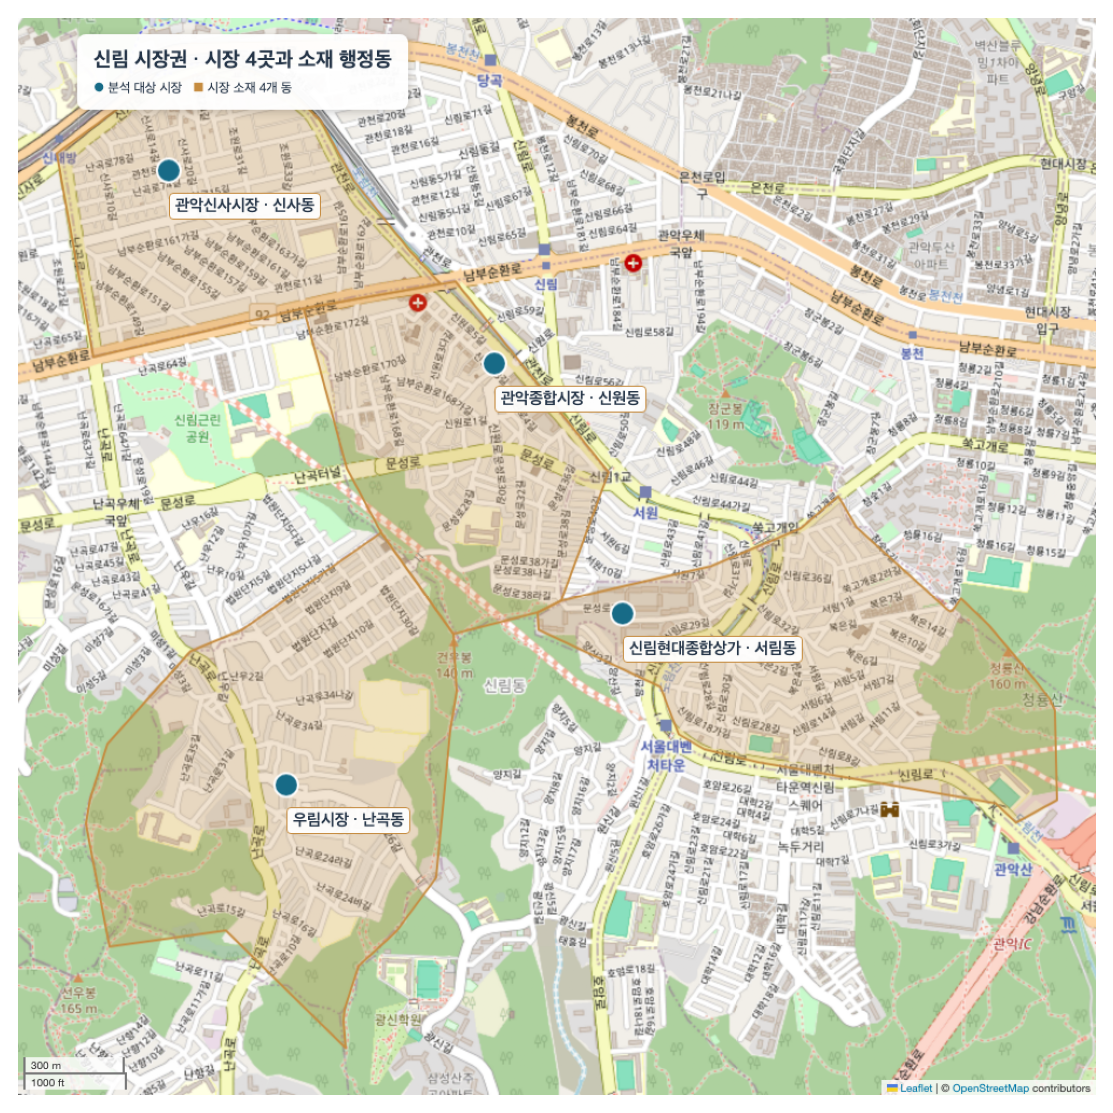

In [3]:
import os, json, tempfile
from plotting import sillim, render_map_png, plot_sillim_map
source_paths = [os.environ.get(name) for name in
                ["BC_MARKET_FEATURES", "BC_HDONG_BOUNDARIES", "BC_HDONG_CENTROIDS"]]
if all(p and Path(p).exists() for p in source_paths):
    features = pd.read_csv(source_paths[0], dtype={"행정기관코드": str})
    boundaries = json.loads(Path(source_paths[1]).read_text())
    centroids = pd.read_csv(source_paths[2], dtype={"행정기관코드": str})
    with tempfile.TemporaryDirectory() as folder:
        map_html = sillim(features, boundaries, centroids, Path(folder))
        map_png = Path(folder) / "map.png"
        render_map_png(map_html, map_png, 1000, 1000)
        plot_sillim_map(map_png)
else:
    print("비공개 시장 위치 입력이 없어 저장된 그림을 표시합니다.")
display(Image(filename=str(FIGS / "fig_v4_3b_sillim_map.png")))

## 요일·시간

,평일,주말
19~23시 귀가 도착 일평균,,
신사동,2370,1866
신원동,3795,3289
서림동,2569,1938
난곡동,2411,1750


신사동      38.8
신원동      37.1
서림동      37.3
난곡동      33.0
전국 평균    30.8
Name: 평일 귀가 도착 중 19~23시 (%), dtype: float64

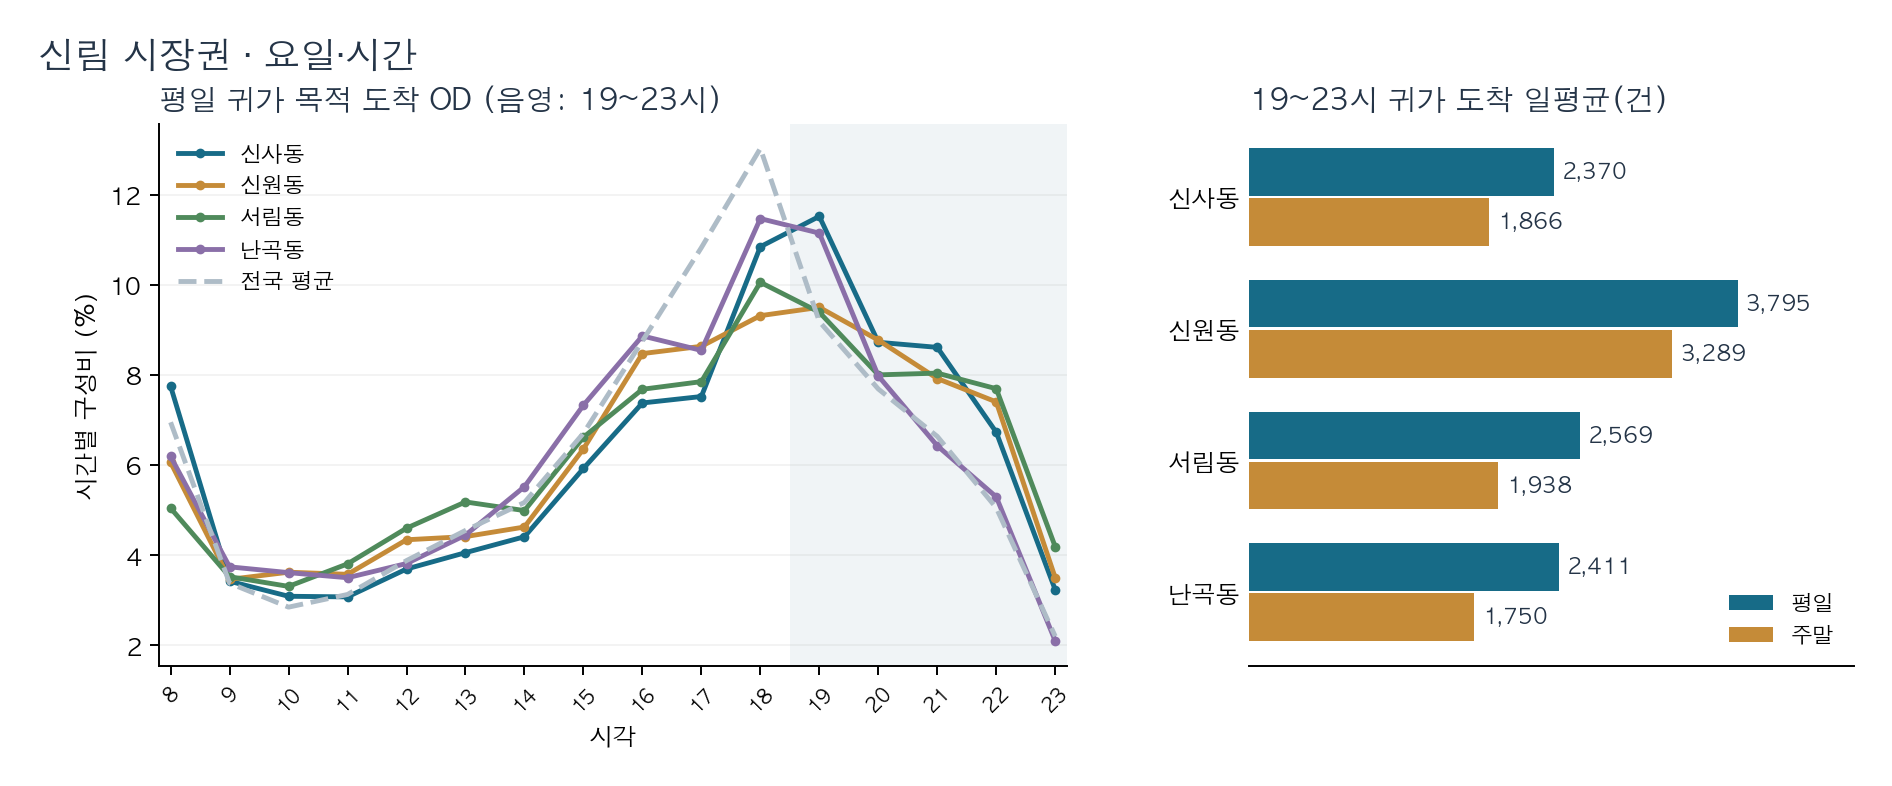

In [4]:
display(pd.DataFrame(SILLIM_HOME_EVENING).T.rename_axis("19~23시 귀가 도착 일평균"))
evening = {name: round(sum(shares[11:]) * 100, 1) for name, shares in SILLIM_HOME_HOURS.items()}
display(pd.Series(evening, name="평일 귀가 도착 중 19~23시 (%)"))
plot_sillim_time()
display(Image(filename=str(FIGS / "fig_v4_3c_sillim_time.png")))

## 제안

* 방안: 평일 저녁 귀가 주민을 겨냥한 장보기 품목 판매를 신림 시장권에서 시범 검토, 관악신사시장부터 시작
* 상태: 시행·효과 미확인